# Assignment Beta — Question 4

Student ID: 23K-0073  


In [ ]:
import math
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

labels = ['Positive', 'Negative', 'Neutral']
zero_shot = np.array([
    [100,  5, 15],
    [  8, 80, 12],
    [ 20, 10, 50]
], dtype=int)
revised = np.array([
    [106, 4, 10],
    [  6,84, 10],
    [  9, 7, 64]
], dtype=int)

for title, matrix in [('Stage 1 — zero-shot', zero_shot),
                      ('Stage 2 — revised prompt', revised)]:
    print(title)
    display(pd.DataFrame(matrix, index=[f'Actual {x}' for x in labels],
                         columns=[f'Pred. {x}' for x in labels]))
    print('Row totals:', matrix.sum(axis=1), '| Column totals:', matrix.sum(axis=0),
          '| Reviews:', matrix.sum(), '\n')
assert zero_shot.sum() == revised.sum() == 300

Stage 1 — zero-shot


,Pred. Positive,Pred. Negative,Pred. Neutral
Actual Positive,100,5,15
Actual Negative,8,80,12
Actual Neutral,20,10,50


Row totals: [120 100  80] | Column totals: [128  95  77] | Reviews: 300 

Stage 2 — revised prompt


,Pred. Positive,Pred. Negative,Pred. Neutral
Actual Positive,106,4,10
Actual Negative,6,84,10
Actual Neutral,9,7,64


Row totals: [120 100  80] | Column totals: [121  95  84] | Reviews: 300 



## 1) Baseline accuracy and a 95% confidence interval

The diagonal gives the number of correct classifications. For Stage 1:

$$\text{Correct}=100+80+50=230$$

$$\hat p=\frac{230}{300}=0.766667\quad\Rightarrow\quad \boxed{76.67\%}$$

For an uncertainty interval, use the **Wilson score interval** rather than treating 76.67% as exact for all future reviews:

$$\mathrm{CI}_{95\%}=\frac{\hat p+z^2/(2n)\;\pm\;z\sqrt{\hat p(1-\hat p)/n+z^2/(4n^2)}}{1+z^2/n}$$

Here $n=300$ and $z=1.96$. We calculate its center and half-width separately so each step is visible.

In [ ]:
def wilson_working(matrix, z=1.96):
    total = int(matrix.sum())
    correct = int(np.trace(matrix))
    share = correct / total
    denominator = 1 + z*z/total
    center_numerator = share + z*z/(2*total)
    uncertainty = z * math.sqrt(share*(1-share)/total + z*z/(4*total*total))
    center = center_numerator/denominator
    half_width = uncertainty/denominator
    lower, upper = center-half_width, center+half_width
    print(f'Correct/total        = {correct}/{total} = {share:.6f}')
    print(f'Wilson denominator   = 1 + {z}²/{total} = {denominator:.6f}')
    print(f'Center numerator     = {share:.6f} + {z*z:.4f}/{2*total} = {center_numerator:.6f}')
    print(f'Adjusted center      = {center_numerator:.6f}/{denominator:.6f} = {center:.6f}')
    print(f'Adjusted half-width  = {uncertainty:.6f}/{denominator:.6f} = {half_width:.6f}')
    print(f'95% Wilson interval  = [{lower:.6f}, {upper:.6f}] = [{lower:.2%}, {upper:.2%}]')
    return share, (lower, upper)

accuracy1, interval1 = wilson_working(zero_shot)

Correct/total        = 230/300 = 0.766667
Wilson denominator   = 1 + 1.96²/300 = 1.012805
Center numerator     = 0.766667 + 3.8416/600 = 0.773069
Adjusted center      = 0.773069/1.012805 = 0.763295
Adjusted half-width  = 0.048288/1.012805 = 0.047677
95% Wilson interval  = [0.715618, 0.810973] = [71.56%, 81.10%]


**Answer 1:** $\boxed{\mathrm{Accuracy}=76.67\%}$ and $\boxed{95\%\ \mathrm{CI}\approx[71.56\%,\ 81.10\%]}$.

This confidence interval uses the standard binomial approximation underlying Wilson's method. It describes sampling uncertainty, not a guarantee about a newly trained model.

## 2) Precision, recall and F1 for each Stage 1 class

Treat each sentiment as a **one-versus-rest** problem. For any class:

$$TP=\text{diagonal entry},\qquad FP=\text{column total}-TP,\qquad FN=\text{row total}-TP$$
$$P=\frac{TP}{TP+FP},\quad R=\frac{TP}{TP+FN},\quad F_1=\frac{2TP}{2TP+FP+FN}$$

For example, for **Positive**:

$$TP=100,\quad FP=8+20=28,\quad FN=5+15=20$$
$$P=100/128=0.781250,\quad R=100/120=0.833333,\quad F_1=200/248=0.806452$$

The same steps are printed for Negative and Neutral below.

In [ ]:
def individual_scores(matrix, title):
    rows = []
    print(title)
    for pos, label in enumerate(labels):
        tp = int(matrix[pos, pos])
        fp = int(matrix[:, pos].sum() - tp)
        fn = int(matrix[pos, :].sum() - tp)
        support = tp + fn
        p = tp/(tp+fp)
        r = tp/(tp+fn)
        f = 2*tp/(2*tp+fp+fn)
        rows.append({'Class': label, 'TP': tp, 'FP': fp, 'FN': fn,
                     'Support': support, 'Precision': p, 'Recall': r, 'F1': f})
        print(f'{label}: TP={tp}, FP={fp}, FN={fn}')
        print(f'   Precision = {tp}/({tp}+{fp}) = {p:.6f}')
        print(f'   Recall    = {tp}/({tp}+{fn}) = {r:.6f}')
        print(f'   F1        = {2*tp}/({2*tp}+{fp}+{fn}) = {f:.6f}')
    result = pd.DataFrame(rows).set_index('Class')
    display(result)
    return result

stage1_metrics = individual_scores(zero_shot, 'Stage 1 breakdown')

Stage 1 breakdown
Positive: TP=100, FP=28, FN=20
   Precision = 100/(100+28) = 0.781250
   Recall    = 100/(100+20) = 0.833333
   F1        = 200/(200+28+20) = 0.806452
Negative: TP=80, FP=15, FN=20
   Precision = 80/(80+15) = 0.842105
   Recall    = 80/(80+20) = 0.800000
   F1        = 160/(160+15+20) = 0.820513
Neutral: TP=50, FP=27, FN=30
   Precision = 50/(50+27) = 0.649351
   Recall    = 50/(50+30) = 0.625000
   F1        = 100/(100+27+30) = 0.636943


,TP,FP,FN,Support,Precision,Recall,F1
Class,,,,,,,
Positive,100,28,20,120,0.781250,0.833333,0.806452
Negative,80,15,20,100,0.842105,0.800000,0.820513
Neutral,50,27,30,80,0.649351,0.625000,0.636943


## 3) Stage 1 macro, weighted and micro F1

Each average answers a different question.

**Macro F1:** every class receives the same importance:

$$F_{1,\mathrm{macro}}=\frac{F_{1,+}+F_{1,-}+F_{1,0}}3$$

**Weighted F1:** each F1 is weighted by how many true examples its class contains; the supports are $120$, $100$ and $80$:

$$F_{1,\mathrm{weighted}}=\frac{120F_{1,+}+100F_{1,-}+80F_{1,0}}{300}$$

**Micro F1:** combine all classwise TP/FP/FN. In this one-label-per-review problem, every mistaken prediction creates one false positive and one false negative, so micro F1 is the same as accuracy.

In [ ]:
def combined_scores(matrix, detail=True):
    tp = np.diag(matrix).astype(float)
    actual = matrix.sum(axis=1).astype(float)
    guessed = matrix.sum(axis=0).astype(float)
    f1 = 2*tp/(actual+guessed)
    macro = np.mean(f1)
    weighted = np.dot(actual, f1)/actual.sum()
    sum_tp = int(tp.sum())
    errors = int(matrix.sum() - sum_tp)
    micro = 2*sum_tp/(2*sum_tp+errors+errors)
    if detail:
        print(f'Macro = ({f1[0]:.6f} + {f1[1]:.6f} + {f1[2]:.6f})/3 = {macro:.6f}')
        print('Weighted = (' + ' + '.join(f'{int(s)}×{v:.6f}' for s,v in zip(actual,f1))
              + f')/{int(actual.sum())} = {weighted:.6f}')
        print(f'Micro = 2×{sum_tp}/(2×{sum_tp}+{errors}+{errors}) = {micro:.6f}')
    return {'Macro F1': macro, 'Weighted F1': weighted, 'Micro F1': micro}

stage1_averages = combined_scores(zero_shot)

Macro = (0.806452 + 0.820513 + 0.636943)/3 = 0.754636
Weighted = (120×0.806452 + 100×0.820513 + 80×0.636943)/300 = 0.765936
Micro = 2×230/(2×230+70+70) = 0.766667


## 4) What Stage 1 gets wrong, and what I would change

The model makes $300-230=70$ errors. Neutral is the weakest class: $30$ of $80$ neutral reviews are assigned another sentiment, and $20$ of those go to Positive. There are also $15$ Positive reviews incorrectly called Neutral.

The biggest two-way mix-up is therefore **Positive versus Neutral**:

$$20+15=35\quad\text{errors, or}\quad\frac{35}{70}=50\%\text{ of all errors}.$$

A sensible change is to explain that *Neutral* includes factual statements, mixed feedback and text with no clear opinion. I'd also add a small balanced set of examples, including reviews that praise the product but criticize delivery. A fixed output format would help prevent answers outside the three labels. This addresses the failure seen in the counts rather than just adding a longer prompt.

## 5) Recalculate everything after improving the prompt

Stage 2 has $106+84+64=254$ correct classifications:

$$\mathrm{Accuracy}_2=\frac{254}{300}=0.846667=\boxed{84.67\%}.$$

Now repeat the same formulas as before. Keeping the method unchanged makes the comparison fair.

In [ ]:
print('Stage 2 accuracy and uncertainty')
accuracy2, interval2 = wilson_working(revised)
print('\nStage 2 classwise scores')
stage2_metrics = individual_scores(revised, 'After prompt revision')
print('\nStage 2 averages')
stage2_averages = combined_scores(revised)

summary_rows = [
    ('Accuracy', accuracy1, accuracy2),
    ('Positive F1', stage1_metrics.loc['Positive','F1'], stage2_metrics.loc['Positive','F1']),
    ('Negative F1', stage1_metrics.loc['Negative','F1'], stage2_metrics.loc['Negative','F1']),
    ('Neutral F1', stage1_metrics.loc['Neutral','F1'], stage2_metrics.loc['Neutral','F1']),
]
summary_rows += [(name,stage1_averages[name],stage2_averages[name])
                 for name in ['Macro F1','Weighted F1','Micro F1']]
comparison = pd.DataFrame(summary_rows,columns=['Metric','Stage 1','Stage 2']).set_index('Metric')
comparison['Absolute change'] = comparison['Stage 2']-comparison['Stage 1']
print('\nStage-by-stage comparison')
display(comparison)
print(f'Accuracy rises by {(accuracy2-accuracy1)*100:.2f} percentage points.')
print(f'Neutral recall rises from {stage1_metrics.loc["Neutral","Recall"]:.1%} to '
      f'{stage2_metrics.loc["Neutral","Recall"]:.1%}.')

Stage 2 accuracy and uncertainty
Correct/total        = 254/300 = 0.846667
Wilson denominator   = 1 + 1.96²/300 = 1.012805
Center numerator     = 0.846667 + 3.8416/600 = 0.853069
Adjusted center      = 0.853069/1.012805 = 0.842284
Adjusted half-width  = 0.041272/1.012805 = 0.040751
95% Wilson interval  = [0.801533, 0.883034] = [80.15%, 88.30%]

Stage 2 classwise scores
After prompt revision
Positive: TP=106, FP=15, FN=14
   Precision = 106/(106+15) = 0.876033
   Recall    = 106/(106+14) = 0.883333
   F1        = 212/(212+15+14) = 0.879668
Negative: TP=84, FP=11, FN=16
   Precision = 84/(84+11) = 0.884211
   Recall    = 84/(84+16) = 0.840000
   F1        = 168/(168+11+16) = 0.861538
Neutral: TP=64, FP=20, FN=16
   Precision = 64/(64+20) = 0.761905
   Recall    = 64/(64+16) = 0.800000
   F1        = 128/(128+20+16) = 0.780488


,TP,FP,FN,Support,Precision,Recall,F1
Class,,,,,,,
Positive,106,15,14,120,0.876033,0.883333,0.879668
Negative,84,11,16,100,0.884211,0.840000,0.861538
Neutral,64,20,16,80,0.761905,0.800000,0.780488



Stage 2 averages
Macro = (0.879668 + 0.861538 + 0.780488)/3 = 0.840565
Weighted = (120×0.879668 + 100×0.861538 + 80×0.780488)/300 = 0.847177
Micro = 2×254/(2×254+46+46) = 0.846667

Stage-by-stage comparison


,Stage 1,Stage 2,Absolute change
Metric,,,
Accuracy,0.766667,0.846667,0.080000
Positive F1,0.806452,0.879668,0.073216
Negative F1,0.820513,0.861538,0.041026
Neutral F1,0.636943,0.780488,0.143545
Macro F1,0.754636,0.840565,0.085929
Weighted F1,0.765936,0.847177,0.081240
Micro F1,0.766667,0.846667,0.080000


Accuracy rises by 8.00 percentage points.
Neutral recall rises from 62.5% to 80.0%.


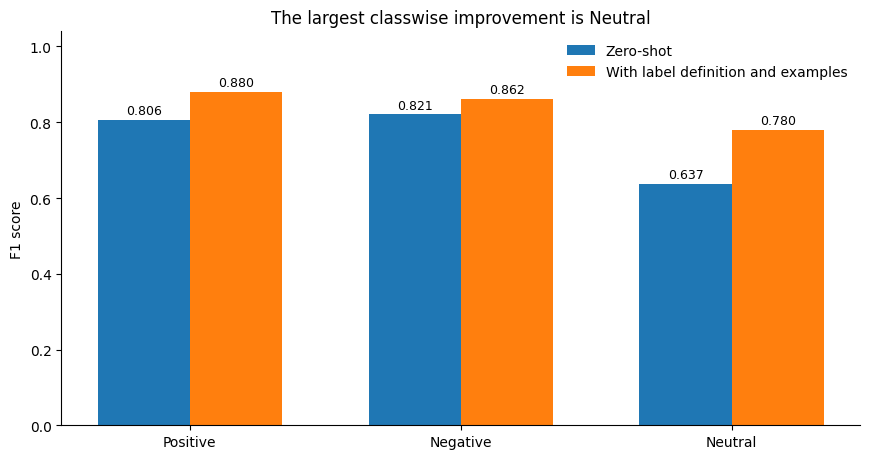

In [ ]:
# One visual comparison: exact values are already printed in the table above.
positions = np.arange(len(labels))
bar_width = 0.34
fig, ax = plt.subplots(figsize=(8.8,4.7))
ax.bar(positions-bar_width/2, stage1_metrics['F1'].values, bar_width, label='Zero-shot')
ax.bar(positions+bar_width/2, stage2_metrics['F1'].values, bar_width, label='With label definition and examples')
for j in range(len(labels)):
    ax.text(positions[j]-bar_width/2, stage1_metrics['F1'].iloc[j]+.015,
            f'{stage1_metrics["F1"].iloc[j]:.3f}',ha='center',fontsize=9)
    ax.text(positions[j]+bar_width/2, stage2_metrics['F1'].iloc[j]+.015,
            f'{stage2_metrics["F1"].iloc[j]:.3f}',ha='center',fontsize=9)
ax.set_xticks(positions, labels)
ax.set_ylim(0,1.04)
ax.set_ylabel('F1 score')
ax.set_title('The largest classwise improvement is Neutral')
ax.legend(frameon=False)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

The gain is **8.00 percentage points in accuracy**. Neutral recall changes from $50/80=62.5\%$ to $64/80=80\%$, exactly the kind of improvement the new prompt was intended to make.

The Wilson confidence intervals are intervals for each stage separately. Since **the same 300 reviews** were evaluated twice, a formal paired significance test would need the per-review pairs of predictions, which are not supplied. The two confusion matrices alone cannot recover that paired information.

## 6) Is Stage 2 sensitive to the order of examples?

Five reported accuracies are:

$$[0.847,\ 0.840,\ 0.853,\ 0.837,\ 0.850]$$

First calculate the mean:

$$\bar x=\frac{0.847+0.840+0.853+0.837+0.850}{5}=\frac{4.227}{5}=\boxed{0.8454}.$$

For the spread, use **sample** standard deviation because these five orderings represent only a subset of possible arrangements:

$$s=\sqrt{\frac{\sum_{i=1}^5(x_i-\bar x)^2}{5-1}}.$$

In [ ]:
ordering_scores = np.array([0.847,0.840,0.853,0.837,0.850])
mean_accuracy = ordering_scores.sum()/len(ordering_scores)
deviations = ordering_scores - mean_accuracy
squares = deviations**2
s_squared = squares.sum()/(len(ordering_scores)-1)
s = math.sqrt(s_squared)

stability = pd.DataFrame({'Ordering': np.arange(1,6),
                          'Accuracy': ordering_scores,
                          'Accuracy - mean': deviations,
                          'Squared difference': squares})
display(stability)
print(f'Mean = {ordering_scores.sum():.6f}/5 = {mean_accuracy:.6f}')
print(f'Sum of squared differences = {squares.sum():.8f}')
print(f'Sample variance = {squares.sum():.8f}/4 = {s_squared:.8f}')
print(f'Sample SD = sqrt({s_squared:.8f}) = {s:.6f}')
print(f'Report: {mean_accuracy:.4f} ± {s:.4f} (sample SD)')
print(f'Range = {ordering_scores.min():.3f}–{ordering_scores.max():.3f} '
      f'({100*(ordering_scores.max()-ordering_scores.min()):.2f} percentage points)')

,Ordering,Accuracy,Accuracy - mean,Squared difference
0,1,0.847000,0.001600,0.000003
1,2,0.840000,-0.005400,0.000029
2,3,0.853000,0.007600,0.000058
3,4,0.837000,-0.008400,0.000071
4,5,0.850000,0.004600,0.000021


Mean = 4.227000/5 = 0.845400
Sum of squared differences = 0.00018120
Sample variance = 0.00018120/4 = 0.00004530
Sample SD = sqrt(0.00004530) = 0.006731
Report: 0.8454 ± 0.0067 (sample SD)
Range = 0.837–0.853 (1.60 percentage points)


**Interpretation:** the mean is **84.54%** and the sample standard deviation is about **0.67 percentage points**. These particular orderings produce similar accuracies, although the 1.6-percentage-point range shows the result is not completely invariant to example order.

## 7) Score the generated justification

The assignment gives one reference and one generated sentence.

**Reference:** `the delivery was late but the product quality is good`  
**Generated:** `the product quality is good but delivery was slow`

Both are already lowercase and have no punctuation, so tokenization simply splits on spaces.

In [ ]:
reference_words = 'the delivery was late but the product quality is good'.split()
generated_words = 'the product quality is good but delivery was slow'.split()
print('Reference length:',len(reference_words), 'tokens')
print('Candidate length:',len(generated_words), 'tokens')
print('Reference tokens:',list(enumerate(reference_words)))
print('Candidate tokens:',list(enumerate(generated_words)))
assert len(reference_words)==10 and len(generated_words)==9

Reference length: 10 tokens
Candidate length: 9 tokens
Reference tokens: [(0, 'the'), (1, 'delivery'), (2, 'was'), (3, 'late'), (4, 'but'), (5, 'the'), (6, 'product'), (7, 'quality'), (8, 'is'), (9, 'good')]
Candidate tokens: [(0, 'the'), (1, 'product'), (2, 'quality'), (3, 'is'), (4, 'good'), (5, 'but'), (6, 'delivery'), (7, 'was'), (8, 'slow')]


### 7(a) BLEU-4, with clipped n-gram counts

For each n-gram length $n=1,2,3,4$:

$$p_n=\frac{\text{clipped matching candidate n-grams}}{\text{candidate n-grams}}.$$

The brevity penalty for a candidate of length $c<r$ is

$$BP=e^{1-r/c},\qquad\text{BLEU-4}=BP\cdot\exp\left(\frac14\sum_{n=1}^4\ln p_n\right).$$

No smoothing is applied because every n-gram precision is nonzero.

In [ ]:
def grams(sequence, n):
    return [tuple(sequence[k:k+n]) for k in range(len(sequence)-n+1)]

bleu_details=[]
for width in range(1,5):
    cgrams=Counter(grams(generated_words,width))
    rgrams=Counter(grams(reference_words,width))
    matches=sum(min(count,rgrams[phrase]) for phrase,count in cgrams.items())
    count=sum(cgrams.values())
    bleu_details.append((width,matches,count,matches/count))

display(pd.DataFrame(bleu_details,columns=['n','Clipped matches','Candidate count','Modified precision']))
precisions=[item[-1] for item in bleu_details]
c,r=len(generated_words),len(reference_words)
penalty=math.exp(min(0,1-r/c))
log_geomean=sum(math.log(p) for p in precisions)/4
bleu4=penalty*math.exp(log_geomean)
print(f'BP = exp(1 - {r}/{c}) = {penalty:.6f}')
print(f'Geometric mean = exp(({" + ".join(f"ln({p:.6f})" for p in precisions)})/4)')
print(f'Geometric mean = {math.exp(log_geomean):.6f}')
print(f'BLEU-4 = {penalty:.6f} × {math.exp(log_geomean):.6f} = {bleu4:.6f}')

,n,Clipped matches,Candidate count,Modified precision
0,1,8,9,0.888889
1,2,5,8,0.625000
2,3,3,7,0.428571
3,4,2,6,0.333333


BP = exp(1 - 10/9) = 0.894839
Geometric mean = exp((ln(0.888889) + ln(0.625000) + ln(0.428571) + ln(0.333333))/4)
Geometric mean = 0.530771
BLEU-4 = 0.894839 × 0.530771 = 0.474955


### 7(b) ROUGE-1, ROUGE-2 and ROUGE-L

ROUGE-1 and ROUGE-2 count shared unigrams and bigrams. ROUGE-L uses the longest common subsequence (LCS), where word order is preserved but gaps are permitted.

For each case, report precision, recall and their F1:

$$P=\frac{m}{\text{candidate units}},\quad R=\frac{m}{\text{reference units}},\quad F_1=\frac{2PR}{P+R}.$$

For ROUGE-L, $m$ is the LCS length rather than a simple n-gram overlap.

In [ ]:
def overlap_ngram(a,b,width):
    shared = Counter(grams(a,width)) & Counter(grams(b,width))
    return sum(shared.values()), len(a)-width+1, len(b)-width+1

def lcs_count(a,b):
    row=[0]*(len(b)+1)
    for x in a:
        next_row=[0]*(len(b)+1)
        for j,y in enumerate(b, start=1):
            next_row[j]=row[j-1]+1 if x==y else max(row[j],next_row[j-1])
        row=next_row
    return row[-1]

def metric_triplet(common,candidate_total,reference_total):
    p=common/candidate_total
    rec=common/reference_total
    return p,rec,2*p*rec/(p+rec) if p+rec else 0

rouge_results={}
for name,(m,ct,rt) in {
    'ROUGE-1':overlap_ngram(generated_words,reference_words,1),
    'ROUGE-2':overlap_ngram(generated_words,reference_words,2),
    'ROUGE-L':(lcs_count(generated_words,reference_words),len(generated_words),len(reference_words)),
}.items():
    p,rec,f1=metric_triplet(m,ct,rt)
    rouge_results[name]=f1
    print(f'{name}: overlap/LCS={m}, candidate units={ct}, reference units={rt}')
    print(f'   P={m}/{ct}={p:.6f}; R={m}/{rt}={rec:.6f}; F1=2×{m}/({ct}+{rt})={f1:.6f}')

ROUGE-1: overlap/LCS=8, candidate units=9, reference units=10
   P=8/9=0.888889; R=8/10=0.800000; F1=2×8/(9+10)=0.842105
ROUGE-2: overlap/LCS=5, candidate units=8, reference units=9
   P=5/8=0.625000; R=5/9=0.555556; F1=2×5/(8+9)=0.588235
ROUGE-L: overlap/LCS=5, candidate units=9, reference units=10
   P=5/9=0.555556; R=5/10=0.500000; F1=2×5/(9+10)=0.526316


### 7(c) METEOR — explicit matching calculation

METEOR gives more weight to **recall** than BLEU and penalizes matches that are scattered across the candidate. We can complete the exact-match version without downloading external language resources.

A useful alignment is:

- `the product quality is good` (one run of five words)
- `but` (one word)
- `delivery was` (two words)

That gives $m=8$ matched tokens in **3 chunks**. The candidate's `slow` does not match the reference's `late` under exact token matching.

With the standard $\alpha=0.9,\beta=3,\gamma=0.5$ parameters:

$$P=\frac89,\quad R=\frac8{10}$$
$$F_{\mathrm{mean}}=\frac{PR}{\alpha P+(1-\alpha)R},\qquad Penalty=\gamma\left(\frac{3}{8}\right)^\beta$$
$$METEOR_{\mathrm{exact}}=(1-Penalty)F_{\mathrm{mean}}.$$

In [ ]:
matched_tokens=8
chunk_count=3
precision_m=matched_tokens/len(generated_words)
recall_m=matched_tokens/len(reference_words)
alpha,beta,gamma=0.9,3,0.5
harmonic=(precision_m*recall_m)/(alpha*precision_m+(1-alpha)*recall_m)
fragmentation=gamma*(chunk_count/matched_tokens)**beta
meteor_exact=harmonic*(1-fragmentation)
print(f'P = 8/9 = {precision_m:.6f} | R = 8/10 = {recall_m:.6f}')
print(f'Weighted harmonic mean = {harmonic:.6f}')
print(f'Chunk penalty = 0.5 × (3/8)^3 = {fragmentation:.6f}')
print(f'METEOR (exact word match) = {harmonic:.6f} × (1 - {fragmentation:.6f}) = {meteor_exact:.6f}')

# NLTK can confirm exact+stemming without internet access.
# Full METEOR requires the optional WordNet corpus for synonym matching.
try:
    from nltk.translate.meteor_score import meteor_score
    class EmptyLexicon:
        def synsets(self, word):
            return []
    check_meteor=meteor_score([reference_words],generated_words,wordnet=EmptyLexicon())
    print(f'NLTK METEOR (stemming, no synonyms) = {check_meteor:.6f}')
except ImportError:
    print('NLTK is optional; it is not installed, so the displayed manual calculation is used.')

P = 8/9 = 0.888889 | R = 8/10 = 0.800000
Weighted harmonic mean = 0.808081
Chunk penalty = 0.5 × (3/8)^3 = 0.026367
METEOR (exact word match) = 0.808081 × (1 - 0.026367) = 0.786774


NLTK METEOR (stemming, no synonyms) = 0.786774


**METEOR qualification:** the value above is the **offline exact-word result**, verified with NLTK's no-WordNet path when NLTK is available. Full NLTK METEOR may additionally credit stemming or WordNet synonym matches. The provided sentence pair alone does not include a synonym lexicon; a WordNet-enabled calculation should be performed if the instructor expects that specific variant.

### Score table and a short interpretation

In [ ]:
text_scores=pd.DataFrame({
    'Metric':['BLEU-4','ROUGE-1 (F1)','ROUGE-2 (F1)','ROUGE-L (F1)','METEOR (exact/offline)'],
    'Score':[bleu4,rouge_results['ROUGE-1'],rouge_results['ROUGE-2'],rouge_results['ROUGE-L'],meteor_exact]
}).set_index('Metric')
display(text_scores)

,Score
Metric,
BLEU-4,0.474955
ROUGE-1 (F1),0.842105
ROUGE-2 (F1),0.588235
ROUGE-L (F1),0.526316
METEOR (exact/offline),0.786774


The two sentences contain much of the same vocabulary, which explains the high ROUGE-1 score. But the two clauses are in a different order, and `slow` replaces `late`. Longer n-gram matches and the LCS are consequently weaker. This does **not** automatically mean the generated explanation is bad: a reader can still understand the positive comment about product quality and the negative comment about delivery.

## 8) Perplexity of the generated explanation

The assignment supplies the probability of each generated token:

$$[0.60,\ 0.40,\ 0.50,\ 0.80,\ 0.70,\ 0.30,\ 0.25,\ 0.50,\ 0.20]$$

Use natural logarithms:

$$H=-\frac{1}{N}\sum_{i=1}^N\ln p_i,\qquad PPL=e^H,\qquad N=9.$$

The table below shows each $\ln p_i$ before summing.

In [ ]:
token_probabilities=np.array([.60,.40,.50,.80,.70,.30,.25,.50,.20])
assert len(token_probabilities)==len(generated_words)
ln_each=np.log(token_probabilities)
prob_table=pd.DataFrame({'Generated word':generated_words,
                         'Model probability':token_probabilities,
                         'ln(probability)':ln_each})
display(prob_table)
ln_sum=ln_each.sum()
negative_log_avg=-ln_sum/len(token_probabilities)
ppl=math.exp(negative_log_avg)
print(f'Sum of log probabilities = {ln_sum:.6f}')
print(f'Mean negative log probability = -({ln_sum:.6f})/9 = {negative_log_avg:.6f}')
print(f'Perplexity = exp({negative_log_avg:.6f}) = {ppl:.6f}')

,Generated word,Model probability,ln(probability)
0,the,0.600000,-0.510826
1,product,0.400000,-0.916291
2,quality,0.500000,-0.693147
3,is,0.800000,-0.223144
4,good,0.700000,-0.356675
5,but,0.300000,-1.203973
6,delivery,0.250000,-1.386294
7,was,0.500000,-0.693147
8,slow,0.200000,-1.609438


Sum of log probabilities = -7.592934
Mean negative log probability = -(-7.592934)/9 = 0.843659
Perplexity = exp(0.843659) = 2.324859


**Answer 8:** $\boxed{PPL\approx2.324859}$. This summarizes how predictable the model's own words were under its assigned probabilities. **It is not a correctness score**: a model can assign high probabilities to a misleading explanation.

## Final checks and answer sheet

This last cell checks the mathematical identities that should always hold, then prints a short table of key answers.

In [ ]:
# Quick consistency checks, independent of the earlier printed explanations.
assert math.isclose(stage1_averages['Micro F1'],accuracy1,abs_tol=1e-12)
assert math.isclose(stage2_averages['Micro F1'],accuracy2,abs_tol=1e-12)
assert stage1_metrics.loc['Neutral','Recall']==0.625
assert stage2_metrics.loc['Neutral','Recall']==0.8
assert math.isclose(float(bleu4), 0.474954953300978, rel_tol=1e-10)
assert math.isclose(float(ppl), 2.324858843, rel_tol=1e-5)
assert math.isclose(float(meteor_exact),0.78677398989899,rel_tol=1e-10)

final_values=[
    ('1. Stage 1 accuracy',f'{accuracy1:.2%}'),
    ('1. Stage 1 95% Wilson CI',f'{interval1[0]:.2%}–{interval1[1]:.2%}'),
    ('3. Stage 1 macro/weighted/micro F1', '/'.join(f'{stage1_averages[k]:.4f}' for k in ('Macro F1','Weighted F1','Micro F1'))),
    ('5. Stage 2 accuracy',f'{accuracy2:.2%}'),
    ('5. Stage 2 95% Wilson CI',f'{interval2[0]:.2%}–{interval2[1]:.2%}'),
    ('5. Stage 2 macro/weighted/micro F1', '/'.join(f'{stage2_averages[k]:.4f}' for k in ('Macro F1','Weighted F1','Micro F1'))),
    ('6. Prompt order mean ± SD',f'{mean_accuracy:.4f} ± {s:.4f}'),
    ('7. BLEU-4',f'{bleu4:.6f}'),
    ('7. ROUGE-1/2/L F1','/'.join(f'{rouge_results[k]:.6f}' for k in ('ROUGE-1','ROUGE-2','ROUGE-L'))),
    ('7. METEOR exact/offline',f'{meteor_exact:.6f}'),
    ('8. Perplexity',f'{ppl:.6f}'),
]
display(pd.DataFrame(final_values,columns=['Part','Result']).set_index('Part'))
print('All numerical self-checks passed.')

,Result
Part,
1. Stage 1 accuracy,76.67%
1. Stage 1 95% Wilson CI,71.56%–81.10%
3. Stage 1 macro/weighted/micro F1,0.7546/0.7659/0.7667
5. Stage 2 accuracy,84.67%
5. Stage 2 95% Wilson CI,80.15%–88.30%
5. Stage 2 macro/weighted/micro F1,0.8406/0.8472/0.8467
6. Prompt order mean ± SD,0.8454 ± 0.0067
7. BLEU-4,0.474955
7. ROUGE-1/2/L F1,0.842105/0.588235/0.526316


All numerical self-checks passed.
